Problem Statement:Air pollution is a major environmental concern that affects human health and the ecosystem. Monitoring air quality and identifying pollution levels are important for taking preventive measures.

The objective of this project is to develop a Machine Learning classification model using the Air Quality Data in India dataset to predict the air quality category based on different pollutant concentrations and environmental attributes.

The project will involve data preprocessing, exploratory data analysis, feature engineering, categorical encoding, feature scaling using RobustScaler, feature selection, and comparison of multiple classification algorithms to identify the best-performing model.



In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler,OneHotEncoder
from sklearn.feature_selection import SelectKBest,f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix,accuracy_score,f1_score,precision_score,recall_score,classification_report

Data Preprocessing

In [3]:
df = pd.read_csv('city_day.csv')
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


In [5]:
df.describe()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [6]:
df.isnull().sum()

,0
City,0
Date,0
PM2.5,4598
PM10,11140
NO,3582
NO2,3585
NOx,4185
NH3,10328
CO,2059
SO2,3854


In [7]:
df.drop_duplicates()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory


Feature Engineering

In [20]:
df.drop(columns=['Date'],inplace=True)
df.dropna(subset=['AQI_Bucket'],inplace=True)
df

,City,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
28,Ahmedabad,83.13,NaN,6.93,28.71,33.72,NaN,6.93,49.52,59.76,0.02,0.00,3.14,209.0,Poor
29,Ahmedabad,79.84,NaN,13.85,28.68,41.08,NaN,13.85,48.49,97.07,0.04,0.00,4.81,328.0,Very Poor
30,Ahmedabad,94.52,NaN,24.39,32.66,52.61,NaN,24.39,67.39,111.33,0.24,0.01,7.67,514.0,Severe
31,Ahmedabad,135.99,NaN,43.48,42.08,84.57,NaN,43.48,75.23,102.70,0.40,0.04,25.87,782.0,Severe
32,Ahmedabad,178.33,NaN,54.56,35.31,72.80,NaN,54.56,55.04,107.38,0.46,0.06,35.61,914.0,Severe
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29526,Visakhapatnam,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good
29527,Visakhapatnam,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory
29528,Visakhapatnam,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory
29529,Visakhapatnam,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory


Outlier detection using boxplots

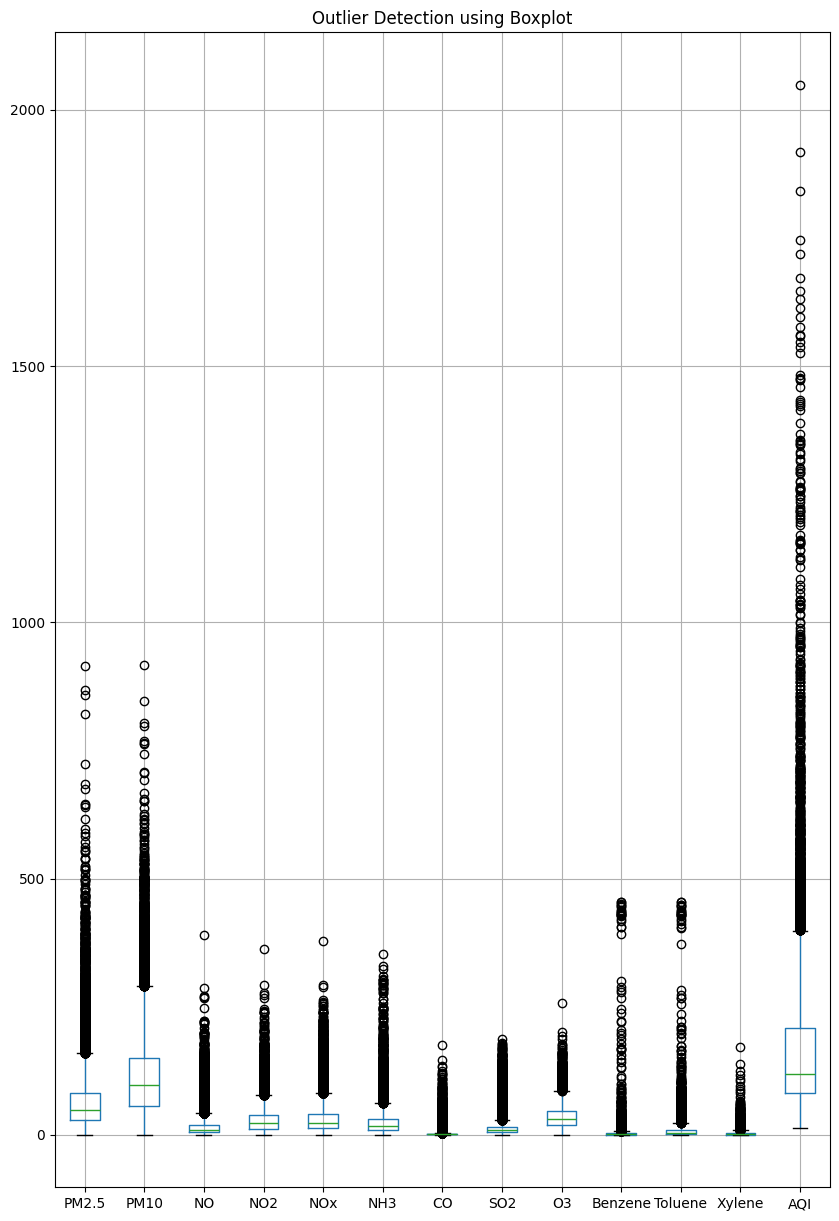

In [21]:
num_cols = df.select_dtypes(include = 'float64').columns
plt.figure(figsize=(10,15))
df[num_cols].boxplot()
plt.title("Outlier Detection using Boxplot")
plt.show()

Not removing extreme pollutant readings automatically. High PM2.5 or PM10 readings may represent actual pollution events.

Visualization

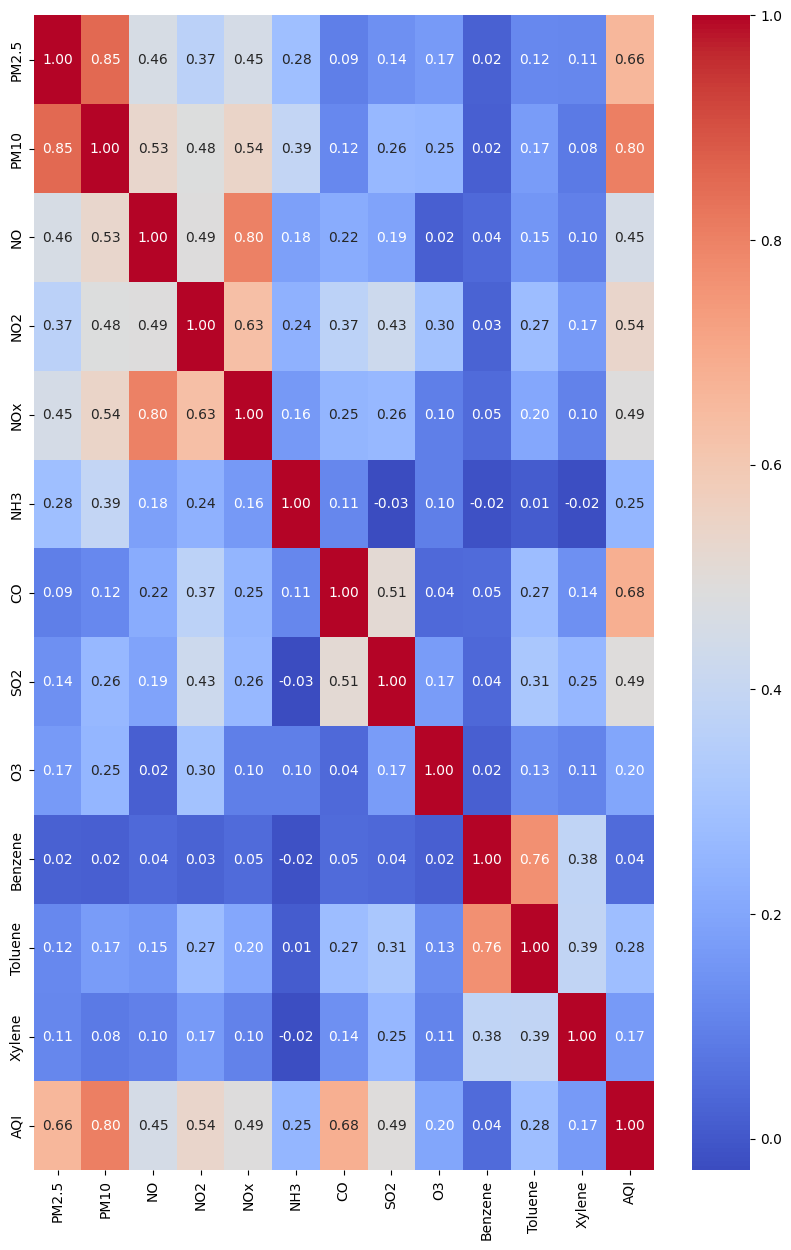

In [23]:
corr=df.select_dtypes(include='float64').corr()
plt.figure(figsize=(10,15))
sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f')
plt.show()



The correlation heatmap illustrates the relationships between the numerical features in the dataset. It helps identify which air pollutants are strongly or weakly correlated with one another. Features with a strong positive correlation tend to increase together, while features with a negative correlation tend to move in opposite directions.

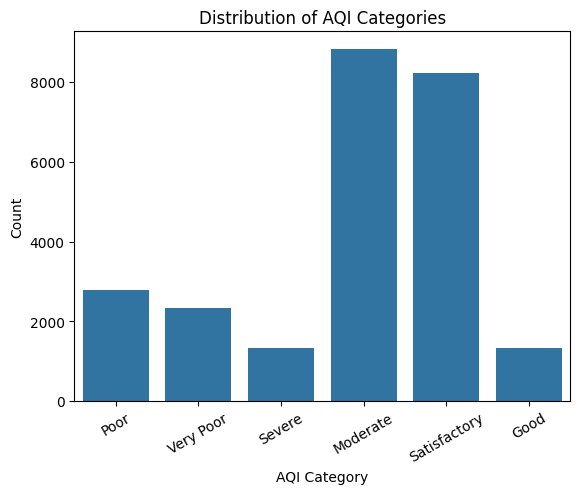

In [24]:
sns.countplot(data=df,x='AQI_Bucket')
plt.title("Distribution of AQI Categories")
plt.xlabel("AQI Category")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.show()

The count plot shows that the Satisfactory and Moderate air quality categories have the highest number of observations in the dataset. The Severe category has the lowest number of observations, indicating that extreme air pollution levels are relatively less frequent. This suggests that the dataset is imbalanced, as some AQI categories are represented much more than other

Separate Input Features and Target

In [39]:
X = df.drop(['AQI_Bucket', 'AQI'], axis=1)
y=df['AQI_Bucket']

The AQI_Bucket is derived from the AQI value. Therefore, if WE use AQI to predict AQI_Bucket, the model gets information that directly reveals the answer. So it is removed

In [50]:
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.2)

Handling Missing Values

In [51]:
num_cols=   X_train.select_dtypes(include ='float64').columns

X_train[num_cols] = X_train[num_cols].fillna(X_train[num_cols].median())
X_test[num_cols] = X_test[num_cols].fillna(X_test[num_cols].median())

cat_cols = X_train.select_dtypes(include=['object']).columns

for col in cat_cols:
  X_train[col] = X_train[col].fillna(X_train[col].mode()[0])
  X_test[col] = X_test[col].fillna(X_test[col].mode()[0])


In [52]:
print("Training missing values:")
print(X_train.isnull().sum())

print("\nTesting missing values:")
print(X_test.isnull().sum())

Training missing values:
City       0
PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
dtype: int64

Testing missing values:
City       0
PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
dtype: int64


One Hot Encoding

In [53]:
X_train = pd.get_dummies(X_train, columns=['City'])
X_test = pd.get_dummies(X_test, columns=['City'])

X_train, X_test = X_train.align(
    X_test, join='left', axis=1, fill_value=0
)

Robust Scaling

In [54]:
scaler = RobustScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

X_test[num_cols] = scaler.transform(X_test[num_cols])

Feature selection

In [55]:
selector= SelectKBest(score_func=f_classif,k=10)
X_train_selected = selector.fit_transform(X_train,y_train)
X_test_selected = selector.transform(X_test)


Model Training and Comparison

In [56]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
    'SVM': SVC()
}

results = []

for name, model in models.items():

    model.fit(X_train_selected, y_train)

    y_pred = model.predict(X_test_selected)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted'),
        'Recall': recall_score(y_test, y_pred, average='weighted'),
        'F1 Score': f1_score(y_test, y_pred, average='weighted')
    })


    results_df = pd.DataFrame(results)

print(results_df.sort_values(by='F1 Score', ascending=False))

                 Model  Accuracy  Precision    Recall  F1 Score
2        Random Forest  0.802616   0.801893  0.802616  0.800826
3                  KNN  0.777867   0.776497  0.777867  0.776600
4                  SVM  0.763581   0.766213  0.763581  0.754253
0  Logistic Regression  0.750302   0.748604  0.750302  0.744356
1        Decision Tree  0.719718   0.718190  0.719718  0.718638


Random Forest: Best performance with 80.26% accuracy. It can capture complex relationships between pollutants and AQI categories.



KNN: Second-best model, with 77.79% accuracy.



SVM: Achieved 76.36% accuracy.



Logistic Regression: Achieved 75.03% accuracy.



Decision Tree: Lowest accuracy among the five models.


HyperparamterTuning for RandomForest

In [57]:
param_grid = {
    'n_estimators': [100, 150, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf = RandomForestClassifier(random_state=42)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='f1_macro',
    random_state=42,

)

random_search.fit(X_train_selected, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV Score:", random_search.best_score_)

Best Parameters: {'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None}
Best CV Score: 0.7776440690988249


HyperparamterTuning for KNN Model

In [61]:
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski'],
    'p': [1, 2]
}

knn = KNeighborsClassifier()

random_search_knn = RandomizedSearchCV(
    estimator=knn,
    param_distributions=param_grid,
    n_iter=20,
    cv=3,
    scoring='f1_macro',
    random_state=42,
    n_jobs=-1
)

random_search_knn.fit(X_train_selected, y_train)
print("Best Parameters:", random_search_knn.best_params_)

print("Best CV Score:", random_search_knn.best_score_)

Best Parameters: {'weights': 'distance', 'p': 1, 'n_neighbors': 7, 'metric': 'manhattan'}
Best CV Score: 0.7398306147361744


Final Model Evaluation after Hyperparameter Tuning

In [59]:
best_rf = random_search.best_estimator_

y_pred = best_rf.predict(X_test_selected)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 Macro:", f1_score(y_test, y_pred, average='macro'))

Accuracy: 0.8062374245472838
F1 Macro: 0.7730446961599453


In [64]:
best_knn = random_search_knn.best_estimator_
y_pred_knn = best_knn.predict(X_test_selected)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))

print("Precision:", precision_score(
    y_test, y_pred_knn, average='weighted'
))

print("Recall:", recall_score(
    y_test, y_pred_knn, average='weighted'
))

print("F1 Weighted:", f1_score(
    y_test, y_pred_knn, average='weighted'
))

print("F1 Macro:", f1_score(
    y_test, y_pred_knn, average='macro'
))


Accuracy: 0.7851106639839034
Precision: 0.7834650267717388
Recall: 0.7851106639839034
F1 Weighted: 0.783642373848796
F1 Macro: 0.7507288999172786


Conclusion :Hyperparameter tuning was performed on the Random Forest and K-Nearest Neighbors (KNN) classification models using RandomizedSearchCV with 3-fold cross-validation.

After tuning, the Random Forest model achieved an accuracy of 80.62% and a Macro F1-score of 77.30%, while the KNN model achieved an accuracy of 78.51% and a Macro F1-score of 75.07%.

The results indicate that Random Forest outperformed KNN in both evaluation metrics. Therefore, Random Forest was selected as the best-performing model among the two tuned classifiers for predicting air quality categories.

The results also demonstrate that hyperparameter optimization can improve model performance by identifying more suitable parameter combinations.